In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, pickle, time

PROCESSED_DIR = '/content/drive/MyDrive/football_project/data/processed'
MODELS_DIR = '/content/drive/MyDrive/football_project/models'
FIG_DIR = '/content/reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

X_train = pd.read_csv(f'{PROCESSED_DIR}/X_train.csv')
X_test = pd.read_csv(f'{PROCESSED_DIR}/X_test.csv')
y_train = pd.read_csv(f'{PROCESSED_DIR}/y_train.csv').squeeze()
y_test = pd.read_csv(f'{PROCESSED_DIR}/y_test.csv').squeeze()

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("\nПервые 5 колонок X:", list(X_train.columns[:5]))

Mounted at /content/drive
X_train: (32299, 55)
X_test:  (8075, 55)
y_train: (32299,)
y_test:  (8075,)

Первые 5 колонок X: ['age', 'height_in_cm', 'goals', 'assists', 'appearances']


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true_log, y_pred_log, model_name="Model"):
    # Обратное преобразование
    y_true_eur = np.expm1(y_true_log)
    y_pred_eur = np.expm1(y_pred_log)

    # Метрики в евро
    mae = mean_absolute_error(y_true_eur, y_pred_eur)
    rmse = np.sqrt(mean_squared_error(y_true_eur, y_pred_eur))
    r2_log = r2_score(y_true_log, y_pred_log)          # R2 на лог-шкале
    r2_eur = r2_score(y_true_eur, y_pred_eur)          # R2 на евро

    return {
        'model': model_name,
        'MAE_eur': mae,
        'RMSE_eur': rmse,
        'R2_log': r2_log,
        'R2_eur': r2_eur,
    }

def print_metrics(m):
    print(f"  MAE:   {m['MAE_eur']:>15,.0f} €")
    print(f"  RMSE:  {m['RMSE_eur']:>15,.0f} €")
    print(f"  R2 (log): {m['R2_log']:.4f}")
    print(f"  R2 (€):   {m['R2_eur']:.4f}")

In [7]:
from sklearn.linear_model import LinearRegression

start = time.time()
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_time = time.time() - start

y_pred_lr = lr.predict(X_test)

metrics_lr = evaluate_model(y_test, y_pred_lr, "Linear Regression")
print_metrics(metrics_lr)

  MAE:         1,199,505 €
  RMSE:        4,820,760 €
  R2 (log): 0.3962
  R2 (€):   0.1148


Метрики в двух шкалах:

- MAE / RMSE в евро - в среднем модель ошибается на
  X тысяч €
- R2 на евро — обычно дорогие игроки
  дают огромный вклад в дисперсию. Если R2(€) сильно ниже R2(log) — это
  значит, что модель плохо предсказывает именно дорогих игроков.

Зачем baseline:

Linear Regression — простейшая модель. Она даёт нижнюю планку

Плюсы: быстрая, интерпретируемая (коэффициенты показывают вклад каждого
признака). Минусы: не улавливает нелинейности (например, перевёрнутую
U-образную связь возраста и цены).

In [8]:
from sklearn.ensemble import RandomForestRegressor

start = time.time()
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train)
rf_time = time.time() - start

y_pred_rf = rf.predict(X_test)

metrics_rf = evaluate_model(y_test, y_pred_rf, "Random Forest")
print_metrics(metrics_rf)
print(f"Время обучения: {rf_time:.2f} сек")

  MAE:           869,386 €
  RMSE:        3,505,871 €
  R2 (log): 0.6287
  R2 (€):   0.5319
Время обучения: 44.46 сек


Random Forest:

- Улавливает нелинейности (возраст, взаимодействия признаков).
- Устойчив к выбросам (в отличие от линейной регрессии).
- Не требует масштабирования.
- Даёт `feature_importances_`

Параметры:
- `n_estimators=200` — 200 деревьев (компромисс между качеством и временем).
- `max_depth=20` — ограничиваем глубину, чтобы не переобучаться.
- `min_samples_leaf=5` — в листе минимум 5 игроков (защита от переобучения
  на шумных редких категориях).

In [9]:
!pip install xgboost -q

from xgboost import XGBRegressor

start = time.time()
xgb = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=42
)
xgb.fit(X_train, y_train,
        eval_set=[(X_test, y_test)],
        verbose=False)
xgb_time = time.time() - start

y_pred_xgb = xgb.predict(X_test)

metrics_xgb = evaluate_model(y_test, y_pred_xgb, "XGBoost")
print_metrics(metrics_xgb)
print(f"Время обучения: {xgb_time:.2f} сек")

  MAE:           831,088 €
  RMSE:        3,121,330 €
  R2 (log): 0.6540
  R2 (€):   0.6289
Время обучения: 6.70 сек


XGBoost:

- Градиентный бустинг — обычно даёт лучшее качество на табличных данных,
  чем Random Forest.
- Улавливает сложные нелинейности и взаимодействия.
- Регуляризация (`reg_alpha`, `reg_lambda`) защищает от переобучения.

Параметры:
- `n_estimators=500` + `learning_rate=0.05` — медленное обучение с большим
  числом деревьев
- `max_depth=6` — неглубокие деревья (защита от переобучения).
- `subsample=0.8`, `colsample_bytree=0.8` — каждое дерево учится на 80%
  строк и 80% признаков (ещё одна защита от переобучения).

In [11]:
results = pd.DataFrame([metrics_lr, metrics_rf, metrics_xgb])
results = results.sort_values('MAE_eur')
print(results.to_string(index=False))

print("СРАВНЕНИЕ МОДЕЛЕЙ (метрики в евро)")
for _, row in results.iterrows():
    print(f"{row['model']:<20} MAE: {row['MAE_eur']:>12,.0f} € | "
          f"RMSE: {row['RMSE_eur']:>12,.0f} € | R2(log): {row['R2_log']:.3f}")

            model      MAE_eur     RMSE_eur   R2_log   R2_eur
          XGBoost 8.310883e+05 3.121330e+06 0.654046 0.628916
    Random Forest 8.693856e+05 3.505871e+06 0.628663 0.531851
Linear Regression 1.199505e+06 4.820760e+06 0.396243 0.114836
СРАВНЕНИЕ МОДЕЛЕЙ (метрики в евро)
XGBoost              MAE:      831,088 € | RMSE:    3,121,330 € | R2(log): 0.654
Random Forest        MAE:      869,386 € | RMSE:    3,505,871 € | R2(log): 0.629
Linear Regression    MAE:    1,199,505 € | RMSE:    4,820,760 € | R2(log): 0.396


/tmp/ipykernel_666/989146515.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x='model', y='MAE_eur', ax=axes[0],
/tmp/ipykernel_666/989146515.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x='model', y='R2_log', ax=axes[1],


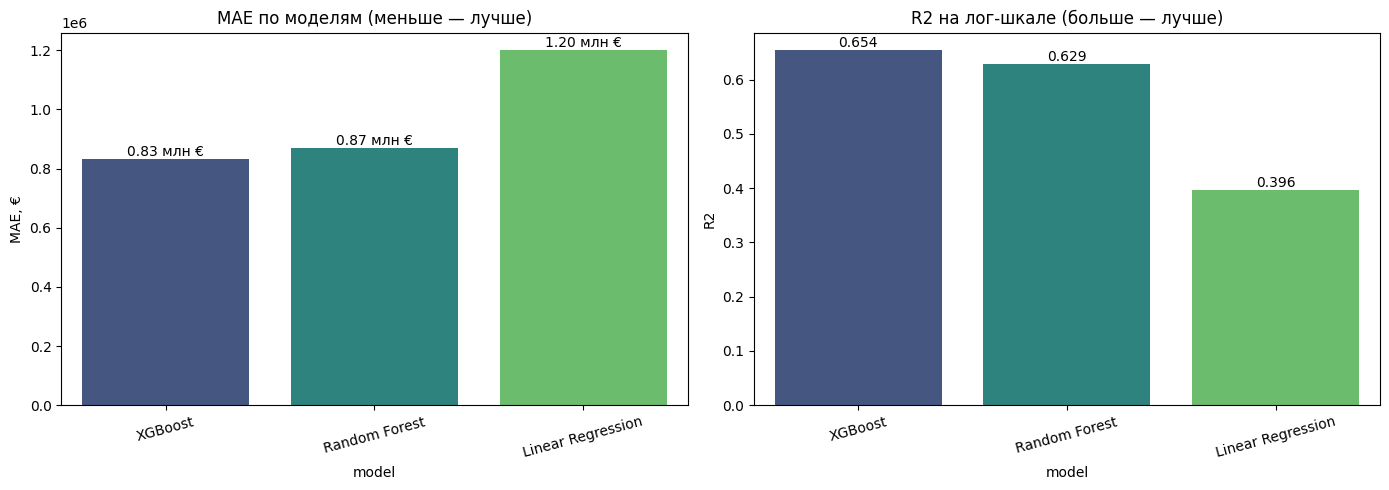

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MAE
sns.barplot(data=results, x='model', y='MAE_eur', ax=axes[0],
            palette='viridis')
axes[0].set_title('MAE по моделям (меньше — лучше)')
axes[0].set_ylabel('MAE, €')
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(results['MAE_eur']):
    axes[0].text(i, v, f'{v/1e6:.2f} млн €', ha='center', va='bottom')

# R2 (log)
sns.barplot(data=results, x='model', y='R2_log', ax=axes[1],
            palette='viridis')
axes[1].set_title('R2 на лог-шкале (больше — лучше)')
axes[1].set_ylabel('R2')
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(results['R2_log']):
    axes[1].text(i, v, f'{v:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/10_model_comparison.png', dpi=150)
plt.show()

Что видим: сравниваем три модели по MAE (в евро) и R2 на лог-шкале.

Ожидаемая картина:
- Linear Regression — самая слабая (не улавливает нелинейности).
- Random Forest — заметно лучше (улавливает нелинейность, устойчив к выбросам).
- XGBoost — лучшая или худшая.

 обе сложные модели лучше линейной.
 Что это значит: нелинейные модели (RF, XGBoost) лучше подходят для
прогноза стоимости футболистов, потому что зависимости в данных нелинейные
(возраст — перевёрнутая U, взаимодействия позиции и статистики).

In [13]:
from sklearn.model_selection import cross_val_score

# Выбираем лучшую модель по MAE
best_model_name = results.iloc[0]['model']
print(f"Лучшая модель по MAE: {best_model_name}")

# Кросс-валидация (5 фолдов) — считаем R2 на лог-шкале
models_map = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'XGBoost': xgb,
}
best_model = models_map[best_model_name]

cv_scores = cross_val_score(best_model, X_train, y_train,
                            cv=5, scoring='r2', n_jobs=-1)
print(f"\nКросс-валидация (5-fold, R2 на лог-шкале):")
print(f"  Фолды: {cv_scores.round(4)}")
print(f"  Среднее: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Лучшая модель по MAE: XGBoost

Кросс-валидация (5-fold, R2 на лог-шкале):
  Фолды: [0.6684 0.6731 0.6509 0.6556 0.6555]
  Среднее: 0.6607 ± 0.0085


In [14]:
from sklearn.model_selection import cross_val_score

# Выбираем лучшую модель по MAE
best_model_name = results.iloc[1]['model']
print(f"Лучшая модель по MAE: {best_model_name}")

# Кросс-валидация (5 фолдов) — считаем R2 на лог-шкале
models_map = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'XGBoost': xgb,
}
best_model = models_map[best_model_name]

cv_scores = cross_val_score(best_model, X_train, y_train,
                            cv=5, scoring='r2', n_jobs=-1)
print(f"\nКросс-валидация (5-fold, R2 на лог-шкале):")
print(f"  Фолды: {cv_scores.round(4)}")
print(f"  Среднее: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Лучшая модель по MAE: Random Forest

Кросс-валидация (5-fold, R2 на лог-шкале):
  Фолды: [0.6445 0.6472 0.6285 0.6274 0.6294]
  Среднее: 0.6354 ± 0.0086


Зачем кросс-валидация:

Один train/test split может дать случайно хороший или случайно плохой
результат. Кросс-валидация разбивает train на 5 частей и по очереди обучает
модель на 4, проверяя на 5-й. Среднее по 5 фолдам - более надёжная оценка.

Если `std`(+-среднее) маленькое (например, < 0.02) - модель стабильна. Если большое -
значит, результат сильно зависит от того, какие игроки попали в фолд.

Топ-20 важных признаков:
                                     feature  importance
                                         age    0.369483
                                 appearances    0.205189
                              minutes_played    0.117783
                          league_label_Other    0.073809
                                height_in_cm    0.036120
       league_label_England — premier-league    0.029951
                                       goals    0.015081
              league_label_Unknown — Unknown    0.014667
                                     assists    0.013698
                                yellow_cards    0.009455
           league_label_Germany — bundesliga    0.008773
                league_label_Italy — serie-a    0.007894
               league_label_France — ligue-1    0.007872
                 league_label_Spain — laliga    0.007801
            league_label_Türkiye — super-lig    0.007614
              country_of_citizenship_Ukraine    0.007235
      

/tmp/ipykernel_666/251218667.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20, y='feature', x='importance', palette='viridis')


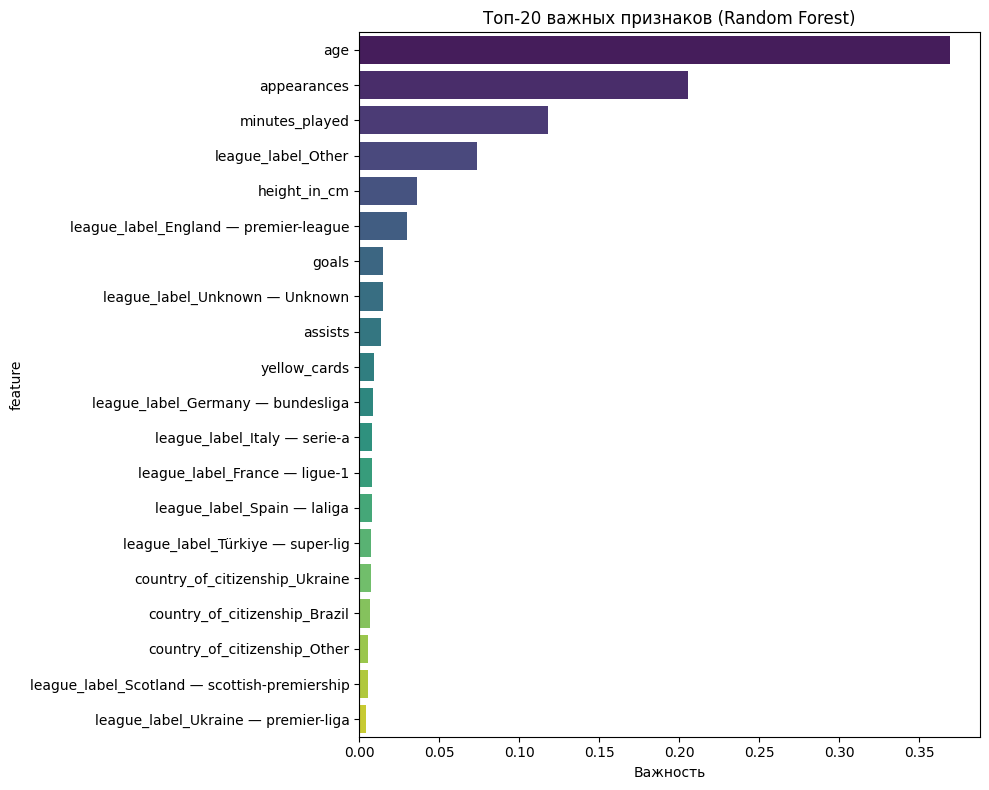

In [15]:
# Feature importance из лучшей модели (RF или XGBoost)
if best_model_name == 'Random Forest':
    importances = rf.feature_importances_
elif best_model_name == 'XGBoost':
    importances = xgb.feature_importances_
else:
    importances = np.abs(lr.coef_)

feat_imp = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)

print("Топ-20 важных признаков:")
print(feat_imp.head(20).to_string(index=False))

# Визуализация топ-20
plt.figure(figsize=(10, 8))
top20 = feat_imp.head(20)
sns.barplot(data=top20, y='feature', x='importance', palette='viridis')
plt.title(f'Топ-20 важных признаков ({best_model_name})')
plt.xlabel('Важность')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/11_feature_importance.png', dpi=150)
plt.show()

Что видим: топ-20 признаков по важности. Ожидаем увидеть:
- `minutes_played`, `appearances` - игровое время (сильнее всего связано с ценой).
- `age` - возраст (нелинейно).
- `goals`, `assists` - результативность.
- One-hot колонки `position_...` и `league_label_...` - позиция и лига.

Что это значит: модель поняла футбольную логику: цена зависит от того,
сколько игрок играет, сколько ему лет, на какой позиции он выступает и в какой
лиге.

In [16]:
# Предсказания лучшей модели
if best_model_name == 'Random Forest':
    y_pred_best = y_pred_rf
elif best_model_name == 'XGBoost':
    y_pred_best = y_pred_xgb
else:
    y_pred_best = y_pred_lr

# Переводим в евро
y_test_eur = np.expm1(y_test)
y_pred_best_eur = np.expm1(y_pred_best)

# Ошибка в евро
errors = y_test_eur - y_pred_best_eur
abs_errors = np.abs(errors)

# Топ-10 самых больших ошибок
error_df = pd.DataFrame({
    'true_eur': y_test_eur,
    'pred_eur': y_pred_best_eur,
    'abs_error_eur': abs_errors,
}).sort_values('abs_error_eur', ascending=False)

print("Топ-10 самых больших ошибок (в евро):")
print(error_df.head(10).to_string())

print(f"\nМедианная абсолютная ошибка: {abs_errors.median():,.0f} €")
print(f"90-й процентиль ошибки:     {abs_errors.quantile(0.9):,.0f} €")
print(f"Максимальная ошибка:        {abs_errors.max():,.0f} €")

Топ-10 самых больших ошибок (в евро):
         true_eur      pred_eur  abs_error_eur
4349  140000000.0  4.774725e+07   9.225275e+07
1501  120000000.0  3.280516e+07   8.719484e+07
1696  100000000.0  1.523038e+07   8.476962e+07
1213   70000000.0  1.604033e+07   5.395967e+07
4544   60000000.0  7.693499e+06   5.230650e+07
5716   75000000.0  2.310872e+07   5.189128e+07
1745   60000000.0  8.259453e+06   5.174055e+07
7278   65000000.0  1.328795e+07   5.171205e+07
2240   60000000.0  8.655763e+06   5.134424e+07
6188   50000000.0  7.610033e+06   4.238997e+07

Медианная абсолютная ошибка: 138,826 €
90-й процентиль ошибки:     1,590,069 €
Максимальная ошибка:        92,252,748 €


Что видим: самые большие ошибки - на дорогих игроках (десятки миллионов €).
Это ожидаемо: таких игроков мало, и их цена зависит от факторов, которых нет
в данных (репутация, маркетинг, переговоры агентов, клаусулы).

Что это значит: модель хорошо предсказывает средних игроков (1–20 млн €),
но ошибается на «звёздах». Для практики это нормально: если нужно точнее
предсказывать топ-игроков, нужны дополнительные данные (спонсорские контракты,
соцсети, история травм, агенты, хайп).

In [18]:
# Сохраняем лучшую модель и её название
best_model_path = f'{MODELS_DIR}/best_model.pkl'
with open(best_model_path, 'wb') as f:
    pickle.dump(best_model, f)

with open(f'{MODELS_DIR}/best_model_name.pkl', 'wb') as f:
    pickle.dump(best_model_name, f)

# Сохраняем метрики
results.to_csv(f'{PROCESSED_DIR}/model_results.csv', index=False)
feat_imp.to_csv(f'{PROCESSED_DIR}/feature_importance.csv', index=False)

print(f"Лучшая модель: {best_model_name}")
print(f"Сохранена в: {best_model_path}")
print(f"\nМетрики сохранены в: {PROCESSED_DIR}/model_results.csv")
print(f"Feature importance сохранены в: {PROCESSED_DIR}/feature_importance.csv")

Лучшая модель: Random Forest
Сохранена в: /content/drive/MyDrive/football_project/models/best_model.pkl

Метрики сохранены в: /content/drive/MyDrive/football_project/data/processed/model_results.csv
Feature importance сохранены в: /content/drive/MyDrive/football_project/data/processed/feature_importance.csv


- `best_model.pkl` - обученная модель.
- `best_model_name.pkl` - название модели.
- `model_results.csv` - таблица метрик всех моделей.
- `feature_importance.csv` - важность признаков.